In [32]:
import pandas as pd
import numpy as np # for mathmatical operations
import seaborn as sns # for visulizations
import matplotlib.pyplot as plt # for graghs
from sklearn.metrics import mean_absolute_error, mean_squared_error# Evaluation

df=pd.read_csv("../data/Complete_Dataset_updated.csv") #read data


In [33]:
df_copy=df.copy()

#Feature selectoin:

#1  :

from sklearn.feature_selection import VarianceThreshold # this is a feature selection method that will help in removing features with the low ver.
from sklearn.model_selection import train_test_split # used for datasplitting

#removing ctigprical columns to be able to calcluate the variences in one step.
df = df.select_dtypes(include=[np.number])



#creating x to store all the columns except the biomass to ensure that all the columns will used for predectipon except the target.
# this 1 axsis is for telling that this is for columns ( 0 if for rows )
X = df.drop(["Biomass"], axis=1) # this is a new df.
y = df["Biomass"]


#Splitting data to be used to build the model then the other part for training it.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
# the random state is for ensuring that each time running the code the same rows will be included.
# 20% is commonly used.

# Calculate the variances of the features
variances = X.var()
#print(variances) # by printing i see the veriances so i choose the threshold
selector_variance = VarianceThreshold(threshold=20000)
# using This function i desicde how much featurs to keep ( the low verisnces will be removed ) ( decide the filter )

selector_variance.fit(X_train)
#fitting is a modle that LEARNS from the input data.
# now by using the fitting i am teching the   selector_variance   by chekcing the varience and deciding

#selecting based on the features passed from my ghteshold.
selected_features = X.columns[selector_variance.get_support()]

# Print the selected features
print("Selected features based on VarianceThreshold:", selected_features)


#2 :
from sklearn.feature_selection import SelectKBest, f_regression


#Splitting data to be used to build the model then the other part for training it.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# instantiate the feature selection model
selector = SelectKBest(f_regression, k=10)

# fit the model ( learn )  on the training data
selector.fit(X_train, y_train)

# transform ( removing the unchosen fraturs ) froom the training and testing sets to keep only the selected features
X_train_selected = selector.transform(X_train)
X_test_selected = selector.transform(X_test)

selected_columns = X.columns[selector.get_support()]
print("Selected features:", selected_columns)



Selected features based on VarianceThreshold: Index(['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11',
       'B12', 'DVI', 'GEMI', 'Radiative_Direct_AVG', 'PPFD'],
      dtype='object')
Selected features: Index(['Lat', 'Animals', 'NDF', 'ADF', 'CP', 'TDN_based_ADF', 'TDN_based_NDF',
       'NDVI', 'NDWI', 'SAVI'],
      dtype='object')


In [34]:
selected_features = ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11',
                     'B12', 'DVI', 'GEMI', 'Radiative_Direct_AVG', 'PPFD', 'Lat', 'Animals',
                     'NDF', 'ADF', 'CP', 'TDN_based_ADF', 'TDN_based_NDF', 'NDVI', 'NDWI', 'SAVI']
df_copy = df[selected_features + ['Biomass']]  # Include target variable

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


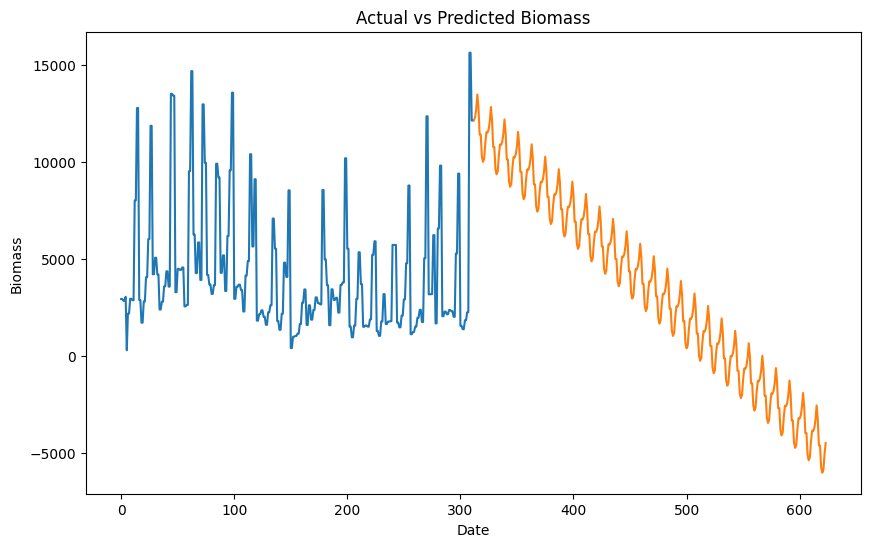

Exponential Smoothing - MAE: 4229.507499078453, MSE: 29598988.821780376, RMSE: 5440.49527357394, rsqured:-3.77963220151506


In [35]:
#Forcasting model 1 : time series
from statsmodels.tsa.holtwinters import ExponentialSmoothing # for forcasting time series data


#print(df['Date'].dtype)# by this way i am figuring the type of the date column , it is obj now so i have to convert it to the

# Convertdatetime format to be able to use the time series functions.
df_copy.dropna()

# Apply Exponential Smoothing
model = ExponentialSmoothing(df_copy['Biomass'], trend='add', seasonal='add', seasonal_periods=12)#building the model
model_fit = model.fit()# THIS IS USING THE TRAINED MODLE ON THE DATA

# Make predictions
y_pred = model_fit.forecast(len(df_copy))# this is predection with the df lenght ( forcasting with the same lenght)
plt.figure(figsize=(10, 6))
plt.plot(df_copy['Biomass'], label='Actual Biomass')
plt.plot(y_pred, label='Predicted Biomass')
plt.title('Actual vs Predicted Biomass')
plt.xlabel('Date')
plt.ylabel('Biomass')
plt.show()

mae = mean_absolute_error(df_copy['Biomass'], y_pred)
mse = mean_squared_error(df_copy['Biomass'], y_pred)
rmse = mean_squared_error(df_copy['Biomass'], y_pred) ** 0.5

# A Problem accoured that the r2 clclauted array with array element by elemtn, when thy are not equal , it cant. SO I MAKE THEM EQUAL.
y_pred = model_fit.forecast(steps=len(y_test))  # Adjust steps to match y_test
r2 = r2_score(y_test, y_pred)

print(f"Exponential Smoothing - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, rsqured:{r2}")



In [36]:
# Split data into features (X) and target variable (y)
X = df_copy[selected_features]  # Features
y = df_copy['Biomass']  # Target variable

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=12)

          Actual    Predicted
201  5532.000000  7052.871972
214  1510.000000  2432.714736
304  1851.000000  4063.426333
144  4816.333333  1429.309813
223  5219.000000  8920.621408
..           ...          ...
41   4370.333333  5195.079211
171  2377.666667  1573.888436
140  1356.666667  2635.146620
244  1731.000000   495.198258
266  1757.333333  1382.632306

[63 rows x 2 columns]
Intercept: 10671195.274831012
Coefficients: [ 1.46308147e+00 -2.40631182e+00 -1.26959235e+00  1.49832907e+01
  1.60222183e+00 -7.27088380e+00  6.52959764e+00 -3.80891061e+00
  1.35747919e+01 -3.17571404e-01 -1.95062829e+01  1.54707029e+00
  4.33731521e+00  5.83114398e-04 -3.81635971e+00 -3.39901920e-01
  2.87765529e+05 -4.88467367e+03 -4.28779516e+04  3.35196640e+04
 -6.86264661e+01  4.30135887e+04 -1.02885422e+05  3.65492169e+08
 -8.97696512e+04 -2.43657115e+08]
Mean Absolute Error: 1309.2402354905976
Mean Squared Error: 2908539.160956076
Root Mean Squared Error: 1705.4439776656623
R-squared: 0.67774565550830

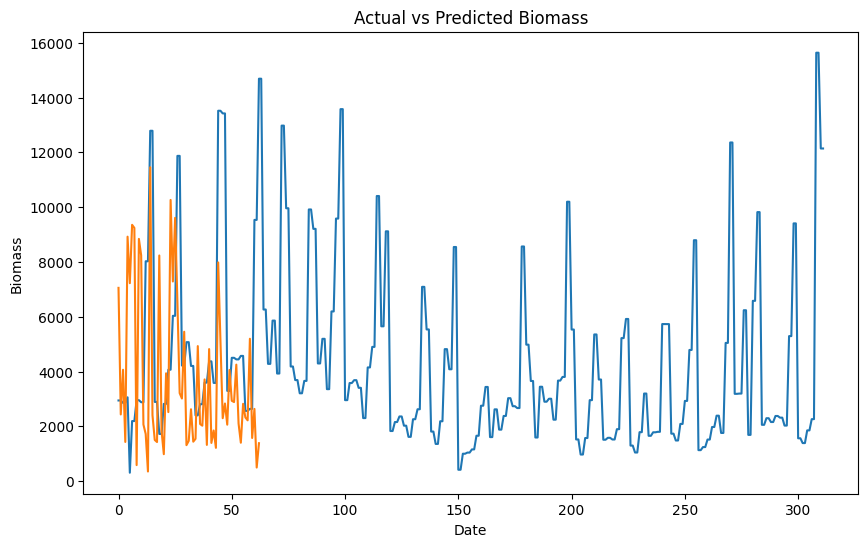

In [37]:
# LINEAR REGRISSION :

from sklearn.linear_model import LinearRegression

regressor = LinearRegression()#creating the model
regressor.fit(X_train, y_train)#train the model on the training data.

y_pred = regressor.predict(X_test)# the trained model is predecting to compare the resylts with the "test data"

# Create a DataFrame to compare actual vs predicted values
df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(df)

# info of the equastion .
print("Intercept:", regressor.intercept_)# this is when x values are 0 ( starting ponit )
print("Coefficients:", regressor.coef_)# this is the slop ( how much y will change if x is changning)

# Evaluate the model using metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print(f'Mean Absolute Error: {mae}')
print(f'Mean Squared Error: {mse}')
print(f'Root Mean Squared Error: {rmse}')
print(f'R-squared: {r2}')


plt.figure(figsize=(10, 6))
plt.plot(df_copy['Biomass'], label='Actual Biomass')
plt.plot(y_pred, label='Predicted Biomass')
plt.title('Actual vs Predicted Biomass')
plt.xlabel('Date')
plt.ylabel('Biomass')
plt.show()


          Actual    Predicted
201  5532.000000  5532.000000
214  1510.000000  1510.000000
304  1851.000000  2261.000000
144  4816.333333  4816.333333
223  5219.000000  5917.333333
..           ...          ...
41   4370.333333  4370.333333
171  2377.666667  2666.000000
140  1356.666667  1356.666667
244  1731.000000  1731.000000
266  1757.333333  1757.333333

[63 rows x 2 columns]
Mean Absolute Error: 325.3333333222222
Mean Squared Error: 472390.2184751632
Root Mean Squared Error: 687.30649529534
R-squared: 0.9476610794028435


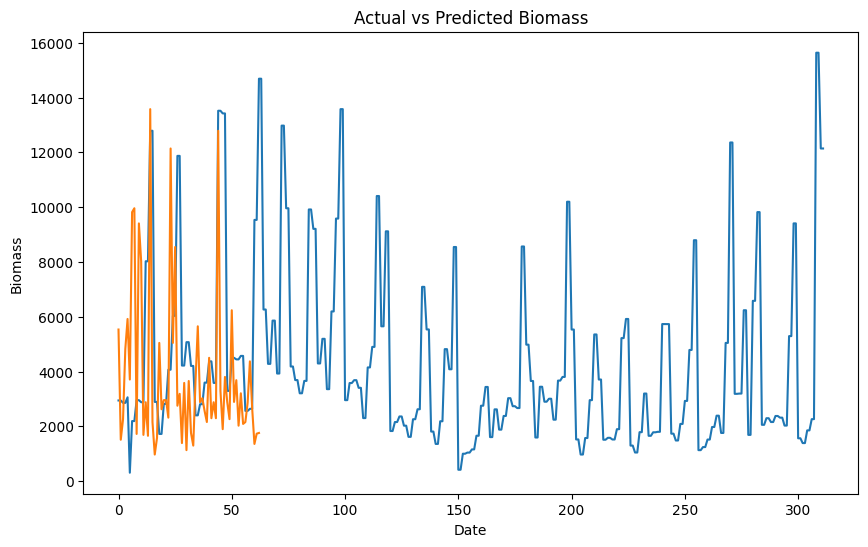

In [38]:
#descion tree model

from sklearn.tree import DecisionTreeRegressor


model = DecisionTreeRegressor()# Creating decision Tree model
model.fit(X_train, y_train)# train it on the training data.

y_pred = model.predict(X_test)# peedection to compare results,

# compare actual with the predicted
dff = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(dff)

# Evaluate the model using metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f'Mean Absolute Error: {mae}')
print(f'Mean Squared Error: {mse}')
print(f'Root Mean Squared Error: {rmse}')
print(f'R-squared: {r2}')

plt.figure(figsize=(10, 6))
plt.plot(df_copy['Biomass'], label='Actual Biomass')
plt.plot(y_pred, label='Predicted Biomass')
plt.title('Actual vs Predicted Biomass')
plt.xlabel('Date')
plt.ylabel('Biomass')
plt.show()

Epoch 1/150


8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 2537474560.0000 - mae: 42509.4492 - val_loss: 128311096.0000 - val_mae: 10006.9268
Epoch 2/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 71645088.0000 - mae: 6621.7007 - val_loss: 104558856.0000 - val_mae: 8307.0547
Epoch 3/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 146990016.0000 - mae: 9665.6846 - val_loss: 64814724.0000 - val_mae: 6494.5220
Epoch 4/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 49844940.0000 - mae: 5277.6313 - val_loss: 12858567.0000 - val_mae: 2274.5720
Epoch 5/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 18617048.0000 - mae: 3124.7546 - val_loss: 22948422.0000 - val_mae: 3739.1509
Epoch 6/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 26234092.0000 - mae: 3763.5544 - val_loss: 13306411.0000 - val_mae: 2862.1343
Epoch 7/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 14358269.0000 - mae: 3015.6980 - val_loss: 10907840.0000 - val_mae: 2438.6243
Epoch 8/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - l

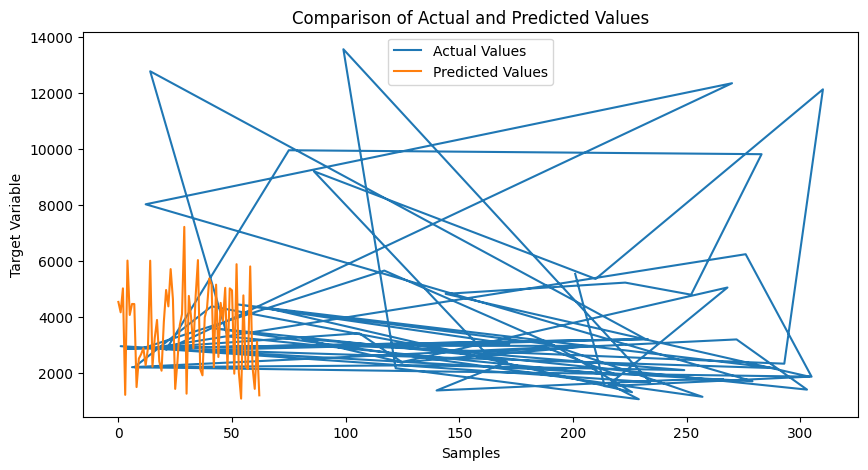

In [41]:

# Forcaating model 3 : deep learning model

#1 : LSTM :

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf

# Normalize the feature data
scaler = MinMaxScaler()# this is about adjusting the values to fit in a cirtin range ( normlization )
X_scaled = scaler.fit_transform(X) # knowing the min and max for each feature , so changing it

  # HERE I AM DONE OF THE DATA PREPROCESSING.


# Reshaping is to formatting input data for LSTM as (samples, timesteps, features)
       #this sample IS HM data rows i have
       #the timesteps is ethe number of data i want to pass per wach model .
       #the featurs is the numer of columns per each sample.. 1 in my code is set to tell that each sample is a single step
#reshaping is becouse this modle deals with the "sequance data",


  #RESHAPING STEP --> needed for the LSTM modle.
  # i use the shape functions becouse it returns the num of columns and rows.
# Convert DataFrame to NumPy array before reshaping
X_train_lstm = X_train.values.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test_lstm = X_test.values.reshape((X_test.shape[0], 1, X_test.shape[1]))


  # BUILD AND TRAIN MODLE
# Building it will use the Sequantial method so it will include leyers above each other.
# here i am building the nural netowrk.
model = tf.keras.Sequential([
    tf.keras.layers.LSTM(64, activation='relu', input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])),
    #here we are building the lstm layer , 64 is its capacity
    #relu is a function that decide which values to keep,
    #then we are telling the shape of the data that will be entered , the first is the timesteps
    #the modle will look at and the other is the number of featurwes the modle will use.
    # THE OVERALL GOAL OF THIS LAYER IS LEARNNING SEQUANSTAL PATTERNS ON MY DATA
    tf.keras.layers.Dense(32, activation='relu'),
    #this is anlother layser where the modle will learn from the data, 32 is the capacity and relu is used again.
    #THE OVERALL GOAL OF THIS LAYER TO LEANR HIGH LEVEL PATTERNS AS A RESLT OF THE LSTM MODLE
    tf.keras.layers.Dense(1)  # the final layer which will give the Single output for regression ( predection result )
])



model.compile(optimizer='adam', loss='mse', metrics=['mae'])
#this using the complie methid , using adam is a methon which adjust the wieghts to enhance thwe accerecy
# then i am giving the mse to tell the modle about the error value --> to be miminized.


#START TRAINING THE MODLE
# i pass the trained on data , the testing data to evalute the error , the epoch is about how many times the modle is going forward and back words.
# the batch size is the num of
history = model.fit(X_train_lstm, y_train, validation_data=(X_test_lstm, y_test), epochs=150, batch_size=32)

loss, mae = model.evaluate(X_test_lstm, y_test)# testing after trainings , here i use tgetesting sets.
#the evalute funcrion return both values.
predictions = model.predict(X_test_lstm)# the generation beased in the testing set.
r2 = r2_score(y_test, predictions)
rmse = mean_squared_error(y_test, y_pred)
# to evalute the modle , the metric mae is used.
print(f"LSTM Loss: {loss}, MAE: {mae}, R-s :{r2}, rmse :{rmse}")

plt.figure(figsize=(10, 5))
plt.plot(y_test, label='Actual Values')
plt.plot(predictions, label='Predicted Values')
plt.title('Comparison of Actual and Predicted Values')
plt.xlabel('Samples')
plt.ylabel('Target Variable')
plt.legend()
plt.show()


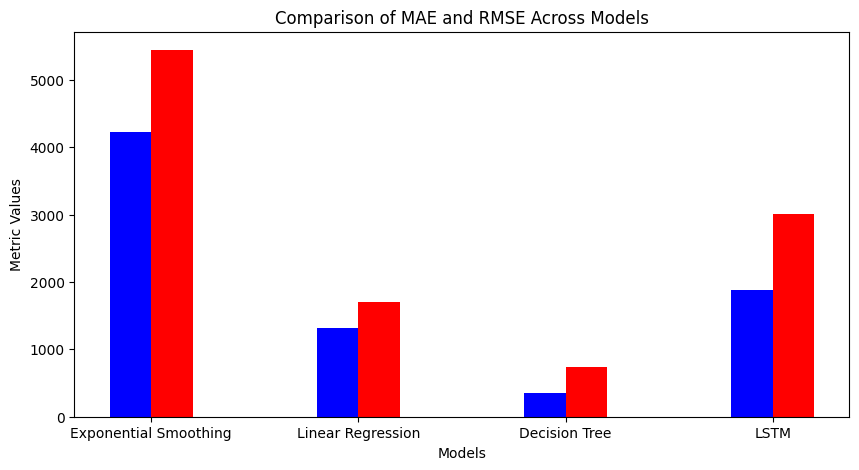

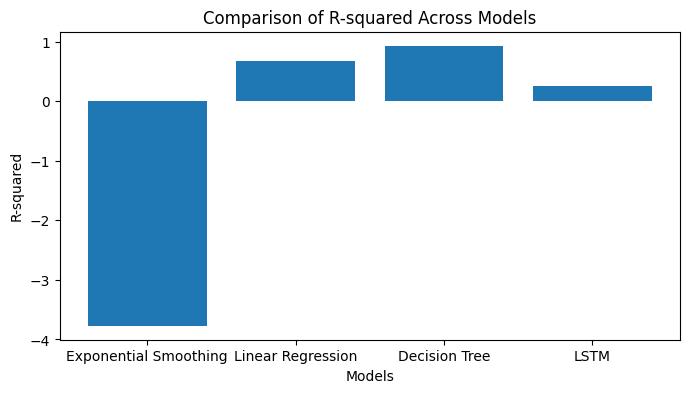

In [42]:
#visulization:
models = ['Exponential Smoothing', 'Linear Regression', 'Decision Tree', 'LSTM']
mae = [4229.5, 1309.2, 358.1, 1886.71]  
rmse = [5440.4, 1705.44, 744.9, 3003.35]  

# the bars posiotn in the x axsis 
x = np.arange(len(models)) #the function creates an array from 0 to the len - 1

plt.figure(figsize=(10, 5))
plt.bar(x - 0.1, mae, width=0.2, label='MAE', color='blue')
plt.bar(x + 0.1, rmse, width=0.2, label='RMSE', color='red')

plt.xlabel('Models')
plt.ylabel('Metric Values')
plt.title('Comparison of MAE and RMSE Across Models')
plt.xticks(x, models)
plt.show()



# THE SEC PLT :
# R-squared values for each model
r_squared = [-3.77, 0.67, 0.93, 0.25]

plt.figure(figsize=(8, 4))
plt.bar(models, r_squared)
plt.xlabel('Models')  
plt.ylabel('R-squared')  
plt.title('Comparison of R-squared Across Models')
plt.show()

